Number of images per category: Counter({1: 561, 2: 416, 0: 120})
Unique dimensions: {(512, 512), (404, 511), (512, 801), (512, 623), (331, 506)}
Number of low-quality images: 0


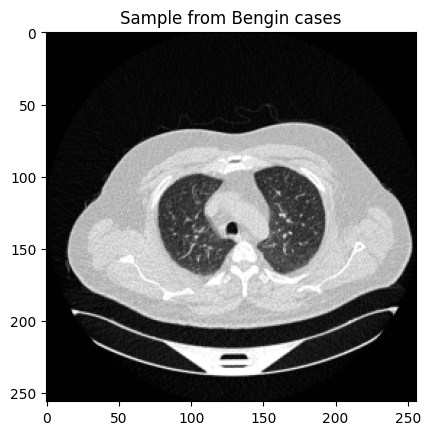

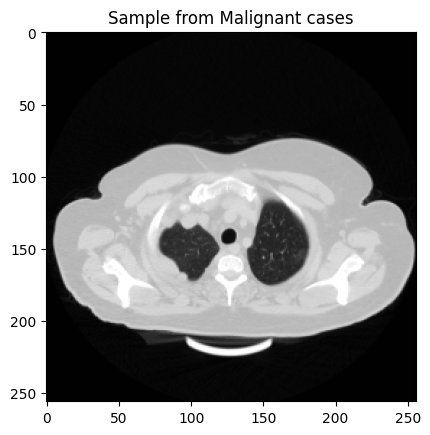

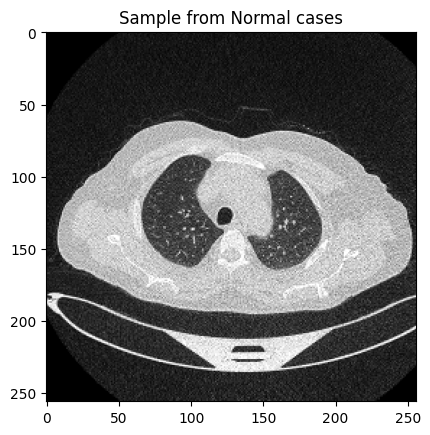

Before SMOTE: Counter({1: 392, 2: 291, 0: 84})
After SMOTE: Counter({2: 392, 1: 392, 0: 392})


In [1]:
    import os
    import cv2
    import numpy as np
    import random
    import matplotlib.pyplot as plt
    from sklearn.model_selection import train_test_split
    from sklearn.utils import shuffle
    from imblearn.over_sampling import SMOTE
    from collections import Counter
    import warnings 
    warnings.filterwarnings("ignore")


    directory = '/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset'


    categories = ["Bengin cases", "Malignant cases", "Normal cases"]


    img_size = 256


    data = []
    labels = []


    low_quality_images = []
    dimensions = []

    for category in categories:
        path = os.path.join(directory, category)
        class_num = categories.index(category)  

        for file in os.listdir(path):
            filepath = os.path.join(path, file)

            try:
                
                img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
                if img is None:
                    continue

                
                dimensions.append(img.shape)

                
                brightness = np.mean(img)
                if brightness < 50:  
                    low_quality_images.append(filepath)
                    continue

                
                img_resized = cv2.resize(img, (img_size, img_size))

                
                data.append(img_resized)
                labels.append(class_num)
            except Exception as e:
                print(f"Error processing file {filepath}: {e}")


    print(f"Number of images per category: {Counter(labels)}")
    print(f"Unique dimensions: {set(dimensions)}")
    print(f"Number of low-quality images: {len(low_quality_images)}")


    for category in categories:
        idx = categories.index(category)
        sample_idx = labels.index(idx)
        plt.imshow(data[sample_idx], cmap="gray")
        plt.title(f"Sample from {category}")
        plt.show()


    data = np.array(data).reshape(-1, img_size, img_size, 1) / 255.0  
    labels = np.array(labels)


    x_temp, x_test, y_temp, y_test = train_test_split(data, labels, test_size=0.2, stratify=labels, random_state=42)


    x_train, x_valid, y_train, y_valid = train_test_split(x_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=42)


    print("Before SMOTE:", Counter(y_train))
    smote = SMOTE(random_state=42)
    x_train_resampled, y_train_resampled = smote.fit_resample(x_train.reshape(-1, img_size * img_size), y_train)
    x_train_resampled = x_train_resampled.reshape(-1, img_size, img_size, 1)
    print("After SMOTE:", Counter(y_train_resampled))




In [2]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


x_train_resampled = np.repeat(x_train_resampled, 3, axis=-1)
x_valid = np.repeat(x_valid, 3, axis=-1)
x_test = np.repeat(x_test, 3, axis=-1)


base_model = EfficientNetV2S(
    include_top=False,  
    weights='imagenet',  
    input_shape=(img_size, img_size, 3)  
)


x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.2)(x)
output_layer = Dense(3, activation='softmax')(x)  


model = Model(inputs=base_model.input, outputs=output_layer)


base_model.trainable = False


model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


model.summary()


callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
]


history = model.fit(
    x_train_resampled, y_train_resampled,
    validation_data=(x_valid, y_valid),
    epochs=25,
    batch_size=32,
    callbacks=callbacks
)


base_model.trainable = True


model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


history_fine_tune = model.fit(
    x_train_resampled, y_train_resampled,
    validation_data=(x_valid, y_valid),
    epochs=25,
    batch_size=32,
    callbacks=callbacks
)


test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.2f}")


82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ rescaling (Rescaling)     │ (None, 256, 256, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_conv (Conv2D)        │ (None, 128, 128, 24)   │            648 │ rescaling[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_bn                   │ (None, 128, 128, 24)   │             96 │ stem_conv[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_activation           │ (None, 128, 128, 24)   │              0 │ stem_bn[0][0]          │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_project_conv      │ (None, 128, 128, 24)   │          5,184 │ stem_activation[0][0]  │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_project_bn        │ (None, 128, 128, 24)   │             96 │ block1a_project_conv[… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_project_activati… │ (None, 128, 128, 24)   │              0 │ block1a_project_bn[0]… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_add (Add)         │ (None, 128, 128, 24)   │              0 │ block1a_project_activ… │
│                           │                        │                │ stem_activation[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1b_project_conv      │ (None, 128, 128, 24)   │          5,184 │ block1a_add[0][0]      │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1b_project_bn        │ (None, 128, 128, 24)   │             96 │ block1b_project_conv[… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1b_project_activati… │ (None, 128, 128, 24)   │              0 │ block1b_project_bn[0]… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1b_drop (Dropout)    │ (None, 128, 128, 24)   │              0 │ block1b_project_activ… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1b_add (Add)         │ (None, 128, 128, 24)   │              0 │ block1b_drop[0][0],    │
│                           │                        │                │ block1a_add[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block2a_expand_conv  

 Total params: 20,335,203 (77.57 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

Epoch 1/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.3514 - loss: 1.0960 - val_accuracy: 0.6091 - val_loss: 0.9884
Epoch 2/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.4938 - loss: 1.0134 - val_accuracy: 0.5364 - val_loss: 0.9606
Epoch 3/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 0.5245 - loss: 0.9781 - val_accuracy: 0.6273 - val_loss: 0.9118
Epoch 4/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 0.5544 - loss: 0.9466 - val_accuracy: 0.5818 - val_loss: 0.8997
Epoch 5/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.5952 - loss: 0.9043 - val_accuracy: 0.5727 - val_loss: 0.8859
Epoch 6/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 0.5545 - loss: 0.9199 - val_accuracy: 0.6091 - val_loss: 0.8684
Epoch 7/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.5674 - loss: 0.9016 - val_accuracy: 0.5909 - val_loss: 0.8630
Epoch 8/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.5780 - loss: 0.8844 - val_accuracy: 0.67

7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step


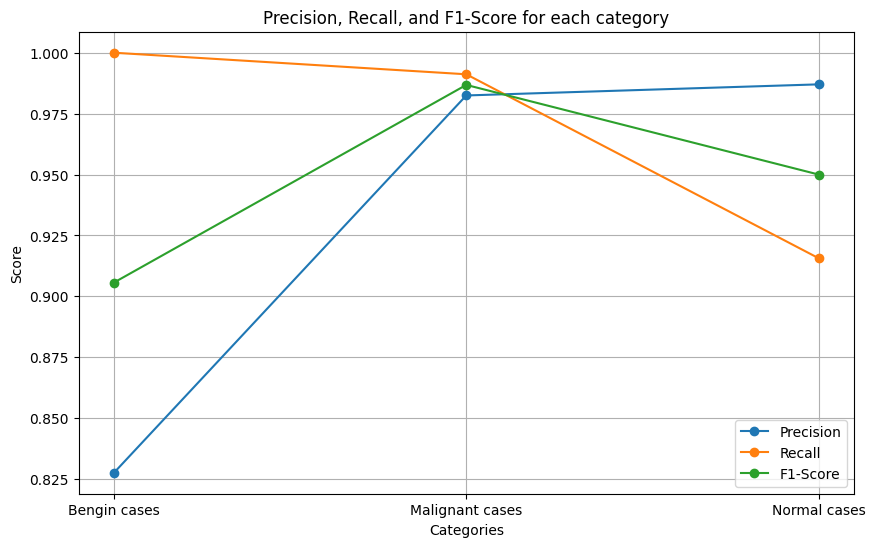

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.83      1.00      0.91        24
Malignant cases       0.98      0.99      0.99       113
   Normal cases       0.99      0.92      0.95        83

       accuracy                           0.96       220
      macro avg       0.93      0.97      0.95       220
   weighted avg       0.97      0.96      0.96       220



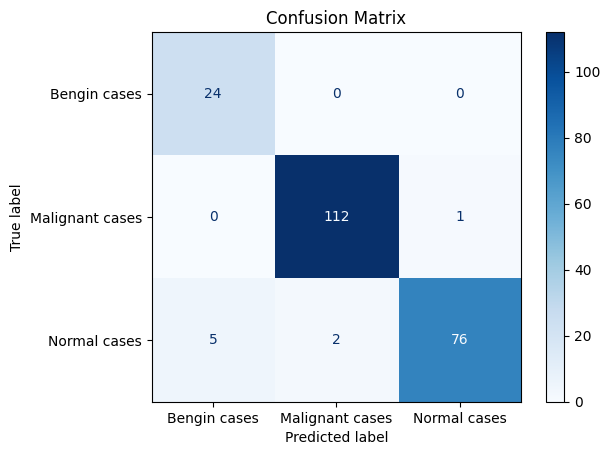

In [3]:
from sklearn.metrics import classification_report, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt


y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)


precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_classes, average=None)


categories = ["Bengin cases", "Malignant cases", "Normal cases"]
plt.figure(figsize=(10, 6))

plt.plot(categories, precision, label="Precision", marker='o')
plt.plot(categories, recall, label="Recall", marker='o')
plt.plot(categories, f1, label="F1-Score", marker='o')

plt.title("Precision, Recall, and F1-Score for each category")
plt.xlabel("Categories")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()


print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=categories))


cm = confusion_matrix(y_test, y_pred_classes)


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()


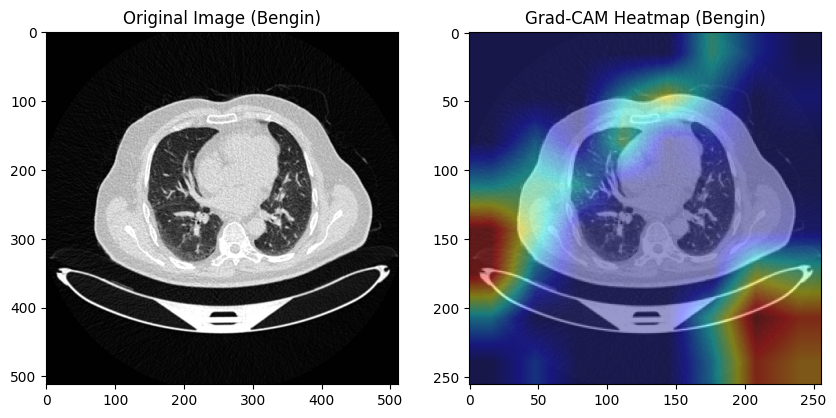

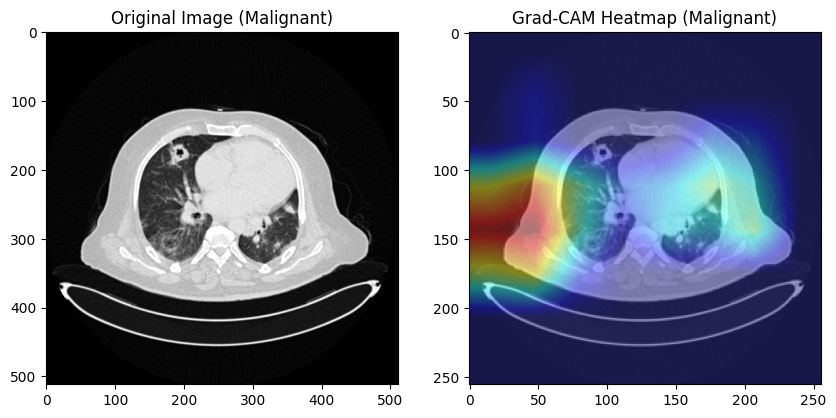

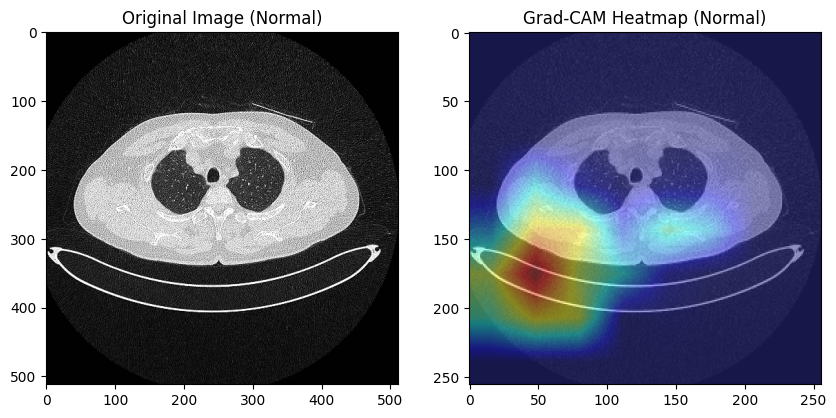

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.models import Model


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = Model(
        inputs=[model.input],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / np.max(heatmap)
    heatmap = np.power(heatmap, 0.8)  
    return heatmap


def apply_gradcam(image_path, label, model, last_conv_layer_name, input_size=(256, 256)):
    
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    img_resized = cv2.resize(img, input_size) / 255.0
    
    img_array = np.expand_dims(np.repeat(img_resized[..., np.newaxis], 3, axis=-1), axis=0)

    
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    
    heatmap_resized = cv2.resize(heatmap, input_size)
    heatmap_resized = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_resized = cv2.cvtColor(heatmap_resized, cv2.COLOR_BGR2RGB)

    
    overlay = cv2.addWeighted(cv2.cvtColor((img_resized * 255).astype('uint8'), cv2.COLOR_GRAY2RGB), 0.6, heatmap_resized, 0.4, 0)

    
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Original Image ({label})")  

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title(f"Grad-CAM Heatmap ({label})")  
    plt.show()


last_conv_layer_name = 'top_conv'  
sample_images = [
    '/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Bengin cases/Bengin case (1).jpg',
    '/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases/Malignant case (106).jpg',
    '/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases/Normal case (101).jpg'
]


labels = ["Bengin", "Malignant", "Normal"]


input_size = (256, 256)  
for image_path, label in zip(sample_images, labels):
    apply_gradcam(image_path, label, model, last_conv_layer_name, input_size=input_size)


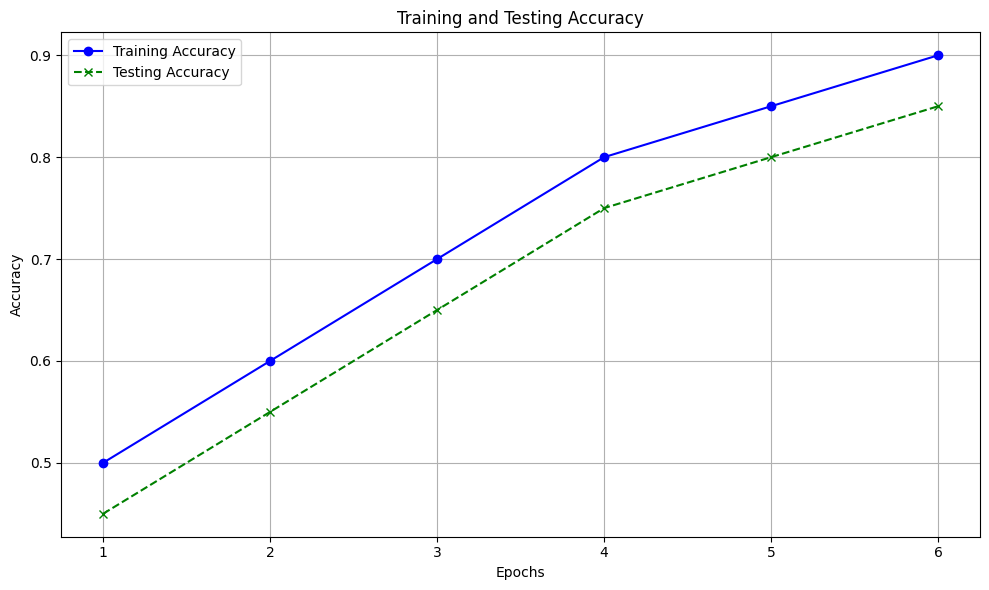

In [5]:
import matplotlib.pyplot as plt

def plot_accuracy(train_acc, test_acc, epochs):
  
    plt.figure(figsize=(10, 6))
    
    
    plt.plot(range(1, epochs + 1), train_acc, label='Training Accuracy', color='blue', linestyle='-', marker='o')
    
    
    plt.plot(range(1, epochs + 1), test_acc, label='Testing Accuracy', color='green', linestyle='--', marker='x')
    
    plt.title('Training and Testing Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


train_acc = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9]  
test_acc = [0.45, 0.55, 0.65, 0.75, 0.8, 0.85]  
epochs = len(train_acc)  


plot_accuracy(train_acc, test_acc, epochs)
